# E6 · Are the rules correct, and do guardrails matter? (live session)

PLAN §9, E6. Baseline: no guardrails. Stream C owns it. This notebook has four parts:

1. **Conflict check**: what the validator says about the shipped rule base.
2. **Scenario test cases**: hand-built members with the firings, allowed offers and blocked offers we expect
   (`tests/fixtures/rule_cases.yaml`, also run by `tests/test_rule_cases.py` as a regression test).
3. **Coverage on the 4,000 real members**: which rules fire, which never do, how often guardrails remove a playbook proposal.
4. **Plan value with vs without guardrails**: Stream B's planners and evaluator on both candidate sets.

Everything is imported from `anchorai`; no rule logic is copied here. Nothing is written to the app DB or to Neo4j; the app DB is read for the W41 caps, the catalogue and contacts staff have logged.
It reads the built data (`uv run anchorai data build`) and the cached KG facts (`uv run anchorai kg load`).

**Caveat (say it wherever these numbers are quoted).** The rule base is **hand-written by the team** and the thresholds
come from the training split of the real data (c_rules.ipynb). The scenario test cases test that the rules do what we
*meant*, not that what we meant is *right*; and because we wrote both, they are optimistic. `trend_ratio` and
`avg_class_frequency_current_month` are suspect features (`results/a_leakage.md`), so rules built on them (D01, D03, P01)
select members partly on information that may come from the churn month. `lost_anchor_instructor`, `class_cancelled`
and `days_since_last_contact` come from the **synthetic scenario layer**, so how often they fire reflects our simulator,
not real gyms.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import yaml

from anchorai.reasoning.engine import load_rule_files, run
from anchorai.reasoning.facts import KNOWN_FACTS
from anchorai.reasoning.service import all_facts
from anchorai.reasoning.validate import validate
from anchorai.scenario.offers import OFFER_CATALOG
from anchorai.schemas import Channel

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG, RES = Path("figures"), Path("results")
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

rules = load_rule_files()
by_id = {r.id: r for r in rules}
offers = [o["offer_id"] for o in OFFER_CATALOG]
print(len(rules), "rules:", pd.Series([r.kind for r in rules]).value_counts().to_dict())

29 rules: {'playbook': 16, 'derive': 8, 'guardrail': 5}


## 1. Conflict check

`validate` flags duplicate ids, unknown facts/offers/channels, unreachable conditions and derive rules that contradict
each other. Expect an empty table for the shipped rule base. A non-empty one is a finding.

In [2]:
issues = validate(rules, KNOWN_FACTS, offers, [c.value for c in Channel])
issues_table = pd.DataFrame([i.model_dump() for i in issues], columns=["rule_id", "severity", "message"])
issues_table.to_csv(RES / "e6_validation_issues.csv", index=False)
print(len(issues), "issues")
issues_table

0 issues


,rule_id,severity,message


## 2. Scenario test cases

Each case is a fact set built by hand (base member + overrides), with the rules we expect to fire, the rules we expect
to stay silent, the offers allowed (in order) and the offers blocked. **Look for:** any row with `ok = False`. Decide
whether the rule or the expectation is wrong; the case file is `tests/fixtures/rule_cases.yaml`.

In [3]:
spec = yaml.safe_load(Path("../backend/tests/fixtures/rule_cases.yaml").read_text())


def case_facts(case):
    base = {k: v for k, v in spec["base"].items() if k not in spec.get("base_drop", [])}
    facts = {**base, **case.get("facts", {})}
    for key in case.get("drop", []):
        facts.pop(key, None)
    return facts


rows = []
for case in spec["cases"]:
    out = run(rules, case_facts(case), case["id"])
    fired = [f.rule_id for f in out.firings]
    want = case["expect"]
    checks = {
        "fires": set(want.get("fires", [])) <= set(fired),
        "silent": not set(want.get("silent", [])) & set(fired),
        "allowed": [p.offer_id for p in out.allowed] == want["allowed"],
        "blocked": out.blocked == want["blocked"] if "blocked" in want else True,
    }
    rows.append({
        "case": case["id"],
        "ok": all(checks.values()),
        "failed": ", ".join(k for k, v in checks.items() if not v),
        "fired": " ".join(r.split("_")[0] for r in fired),
        "allowed": ", ".join(p.offer_id for p in out.allowed),
        "blocked": ", ".join(f"{k}<-{v.split('_')[0]}" for k, v in out.blocked.items()),
        "title": case["title"],
    })
cases_table = pd.DataFrame(rows)
cases_table.to_csv(RES / "e6_scenario_cases.csv", index=False)
print(f"{cases_table['ok'].sum()} / {len(cases_table)} cases match")
cases_table

29 / 29 cases match


,case,ok,failed,fired,allowed,blocked,title
0,steady_low_risk,True,,G03 G04,,"discount_1m<-G03, free_pt_session<-G04, class_...","Steady, low-risk member needs nothing"
1,new_and_slipping_medium,True,,D02 P01 P08,"free_pt_session, checkin_message",,"New member whose visits are falling, medium ri..."
2,high_value_at_risk,True,,G03 D05 P06,free_pt_session,discount_1m<-G03,High-value member at high risk gets a PT sessi...
3,month_to_month_high_risk,True,,D05 P06 P05,"free_pt_session, discount_1m",,Month-to-month member at high risk is high-val...
4,discount_never_proposed_off_month_to_month,True,,G03,,discount_1m<-G03,High risk on a 12-month contract below the hig...
5,recently_contacted,True,,G01 G03 D05 P06,,"all<-G01, discount_1m<-G03",A playbook proposes but the contact-fatigue gu...
6,contact_30_days_ago,True,,G03 D05 P06,free_pt_session,discount_1m<-G03,Exactly 30 days since the last contact is allo...
7,offer_cap_reached,True,,G02 G03 D05 P06,,"all<-G02, discount_1m<-G03",Two offers in 90 days blocks everything even w...
8,never_contacted,True,,G03 D05 P06,free_pt_session,discount_1m<-G03,A never-contacted member has no days-since fac...
9,pt_last_90d,True,,G05 D05 P06 P05,discount_1m,free_pt_session<-G05,A recent free PT session blocks another one bu...


Cases that are **not** testable with the shipped fact vocabulary (findings, not failures):

- **Opted-out members.** There is no opt-out / consent fact in `KNOWN_FACTS` and no guardrail for it, so "never contact a
  member who opted out" cannot be expressed or tested. Decided 2026-10-16: **out of scope**; the report
  states that consent / opt-out handling is assumed to happen in the gym's messaging tool, not in AnchorAI.
- **Instructor left, member never attended their classes.** Covered upstream by the KG signal, not by a rule.

## 3. Coverage on the real members

`all_facts(session)` builds facts for every member exactly as the API does: Stream A's built tables, the cached KG facts,
the W41 contact caps and the contacts logged in the app (B's demo week after `anchorai db reset`).

In [4]:
from sqlmodel import Session

from anchorai.db.session import get_engine

with Session(get_engine()) as session:
    facts = all_facts(session)
outcomes = {m: run(rules, f, m) for m, f in facts.items()}
n = len(outcomes)
print(n, "members")

fired = pd.Series([f.rule_id for o in outcomes.values() for f in o.firings]).value_counts()
coverage = pd.DataFrame({
    "kind": [r.kind for r in rules],
    "members": [int(fired.get(r.id, 0)) for r in rules],
}, index=[r.id for r in rules])
coverage["share"] = coverage["members"] / n
coverage["never_fires"] = coverage["members"] == 0
coverage.round(3).to_csv(RES / "e6_rule_coverage.csv")
print("rules that never fire:", coverage.index[coverage["never_fires"]].tolist())
coverage.round(3)

4000 members
rules that never fire: []


,kind,members,share,never_fires
D01_falling_regular,derive,72,0.018,False
D02_new_member,derive,1330,0.332,False
D03_disengaged,derive,315,0.079,False
D04_new_and_absent,derive,258,0.064,False
D05_high_value_at_risk,derive,957,0.239,False
D06_social_member,derive,1234,0.308,False
D07_lost_instructor,derive,186,0.046,False
D08_class_cancelled,derive,170,0.042,False
G01_contact_fatigue,guardrail,657,0.164,False
G02_offer_cap,guardrail,45,0.011,False


A rule that never fires is either redundant or a symptom of the scenario layer. Check the inputs of each such rule
below before deciding.

In [5]:
never = coverage.index[coverage["never_fires"]].tolist()
for rule_id in never:
    for c in by_id[rule_id].conditions:
        values = pd.Series([f[c.fact] for f in facts.values() if c.fact in f])
        print(rule_id, "|", c, "|", f"{len(values)}/{n} members have it;", values.describe().round(2).to_dict() if pd.api.types.is_numeric_dtype(values) and values.dtype != bool else values.value_counts().to_dict())

### How often do guardrails remove a proposal?

For every member: what the playbooks proposed (`proposals`) versus what survived the guardrails (`allowed`).
`blocked_by` attributes each removed proposal to the guardrail that blocked it (the engine records the first guardrail
per target).

In [6]:
removed = []
for m, o in outcomes.items():
    for p in o.proposals:
        by = o.blocked.get("all") or o.blocked.get(p.offer_id)
        if by:
            removed.append({"member": m, "playbook": p.rule_id, "offer": p.offer_id, "blocked_by": by})
removed = pd.DataFrame(removed)

n_proposals = sum(len(o.proposals) for o in outcomes.values())
print(f"{n_proposals} proposals over {sum(bool(o.proposals) for o in outcomes.values())} members; "
      f"{len(removed)} proposals removed by guardrails ({len(removed) / n_proposals:.1%})")
by_guard = (removed.groupby("blocked_by").agg(proposals_removed=("member", "size"), members=("member", "nunique"))
            .reindex([r.id for r in rules if r.kind == "guardrail"]).fillna(0).astype(int))
by_guard["members_matching_guardrail"] = coverage.loc[by_guard.index, "members"]
by_guard.to_csv(RES / "e6_guardrail_bites.csv")
by_guard

3448 proposals over 1422 members; 1080 proposals removed by guardrails (31.3%)


,proposals_removed,members,members_matching_guardrail
blocked_by,,,
G01_contact_fatigue,1029,372,657
G02_offer_cap,0,0,45
G03_discount_eligibility,0,0,1793
G04_low_risk_no_paid_offers,7,7,2861
G05_pt_eligibility,44,30,353


In [7]:
pd.crosstab(removed["playbook"], removed["blocked_by"], margins=True) if len(removed) else "nothing removed"

blocked_by,G01_contact_fatigue,G04_low_risk_no_paid_offers,G05_pt_eligibility,All
playbook,,,,
P01_new_member_onboarding,161,6,14,181
P01b_new_member_onboarding_in_person,13,1,0,14
P02_falling_regular_checkin,21,0,0,21
P02b_falling_regular_checkin_email,1,0,0,1
P03_disrupted_checkin,68,0,0,68
P03b_disrupted_checkin_email,6,0,0,6
P04_social_class_pass,34,0,0,34
P04b_social_class_pass_email,6,0,0,6
P05_month_to_month_discount,262,0,0,262


### Where do members end up?

Each member falls in exactly one bucket: has an allowed offer; had proposals but guardrails removed all of them; or no
playbook proposed anything. **Look for:** how many high-risk members have no allowed offer, and why.

In [8]:
def bucket(o):
    if o.allowed:
        return "has allowed offer"
    if o.proposals:
        return "blocked: all" if "all" in o.blocked else "blocked: offer-level"
    return "no playbook matched"


outcome_table = pd.DataFrame({
    "bucket": pd.Series({m: bucket(o) for m, o in outcomes.items()}),
    "risk_band": pd.Series({m: o.facts["risk_band"] for m, o in outcomes.items()}),
})
by_band = pd.crosstab(outcome_table["risk_band"], outcome_table["bucket"], margins=True).reindex(["high", "medium", "low", "All"])
by_band.to_csv(RES / "e6_member_outcomes.csv")
by_band

bucket,blocked: all,blocked: offer-level,has allowed offer,no playbook matched,All
risk_band,,,,,
high,298,1,670,1,970
medium,27,0,142,0,169
low,47,4,233,2577,2861
All,372,5,1045,2578,4000


In [9]:
nothing = outcome_table["bucket"] != "has allowed offer"
print(f"members with no allowed offer: {nothing.sum()} ({nothing.mean():.1%}); "
      f"of high-risk members: {(nothing & (outcome_table['risk_band'] == 'high')).sum()} / {(outcome_table['risk_band'] == 'high').sum()}")
print("offers_last_90d:", pd.Series([f.get("offers_last_90d", 0) for f in facts.values()]).value_counts().sort_index().to_dict())
print("days_since_last_contact < 30:", sum(f.get("days_since_last_contact", 999) < 30 for f in facts.values()), "| never contacted:", sum("days_since_last_contact" not in f for f in facts.values()))

members with no allowed offer: 2955 (73.9%); of high-risk members: 300 / 970
offers_last_90d: {0: 2474, 1: 1481, 2: 45}
days_since_last_contact < 30: 657 | never contacted: 2452


### Without guardrails

The same playbooks with the guardrails switched off (still the real engine and real rules; `enabled=False` is a field on
the rule). This is the *count* version of the baseline: how many contacts a guardrail-free system would make that the
guardrails forbid. The *value* version is part 4.

In [10]:
no_guard = [r.model_copy(update={"enabled": False}) if r.kind == "guardrail" else r for r in rules]
free = {m: run(no_guard, f, m) for m, f in facts.items()}
rule_kinds = {r.id: r for r in rules}

rows = []
for m, o in outcomes.items():
    for p in free[m].allowed:
        kept = any(a.offer_id == p.offer_id for a in o.allowed)
        rows.append({"member": m, "offer": p.offer_id, "kept": kept,
                     "violates": "" if kept else (o.blocked.get("all") or o.blocked.get(p.offer_id))})
free_offers = pd.DataFrame(rows)
summary = pd.DataFrame({
    "members_with_offer": [sum(bool(o.allowed) for o in free.values()), sum(bool(o.allowed) for o in outcomes.values())],
    "offers_total": [len(free_offers), int(free_offers["kept"].sum())],
}, index=["no guardrails", "with guardrails"])
summary["share_of_offers_removed"] = [0.0, 1 - free_offers["kept"].mean()]
summary.round(3).to_csv(RES / "e6_with_vs_without_guardrails.csv")
print(free_offers.loc[~free_offers["kept"], "violates"].value_counts().to_dict())
summary.round(3)

{'G01_contact_fatigue': 845, 'G05_pt_eligibility': 30, 'G04_low_risk_no_paid_offers': 7}


,members_with_offer,offers_total,share_of_offers_removed
no guardrails,1422,2907,0.000
with guardrails,1045,2025,0.303


In [11]:
fired_free_offers = free_offers[~free_offers["kept"]]
pd.crosstab(fired_free_offers["offer"], fired_free_offers["violates"], margins=True)

violates,G01_contact_fatigue,G04_low_risk_no_paid_offers,G05_pt_eligibility,All
offer,,,,
checkin_message,218,0,0,218
class_pass,40,0,0,40
discount_1m,288,0,0,288
free_pt_session,299,7,30,336
All,845,7,30,882


### Figure

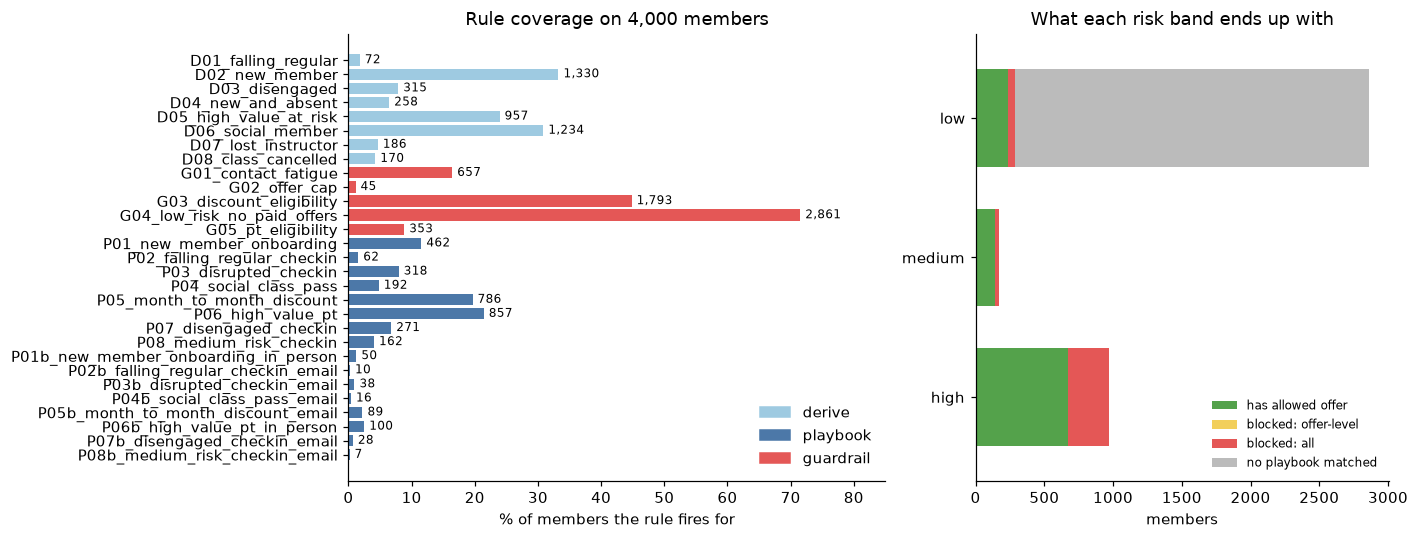

In [12]:
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.3, 1]})
colour = {"derive": "#9ecae1", "playbook": "#4c78a8", "guardrail": "#e45756"}
cov = coverage.iloc[::-1]
a.barh(cov.index, cov["share"] * 100, color=[colour[k] for k in cov["kind"]])
for y, (share, m) in enumerate(zip(cov["share"], cov["members"])):
    a.text(share * 100 + 0.8, y, f"{m:,}" if m else "0  never fires", va="center", fontsize=8)
a.set_xlabel("% of members the rule fires for")
a.set_xlim(0, 85)
a.set_title("Rule coverage on 4,000 members")
a.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in colour.values()], labels=colour.keys(), loc="lower right", frameon=False)

order = ["has allowed offer", "blocked: offer-level", "blocked: all", "no playbook matched"]
shade = {"has allowed offer": "#54a24b", "blocked: offer-level": "#f2cf5b", "blocked: all": "#e45756", "no playbook matched": "#bbbbbb"}
t = by_band.drop(columns="All", index="All").reindex(columns=order, fill_value=0)
t.plot.barh(stacked=True, ax=b, color=[shade[c] for c in t.columns], width=0.7)
b.set_xlabel("members")
b.set_ylabel("")
b.set_title("What each risk band ends up with")
b.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "e6_rule_coverage.png", bbox_inches="tight")

## 4. Plan value with vs without guardrails

How much does a plan gain or lose when the guardrails are removed from its candidates? This uses Stream B's pipeline as the
app does, changing only the candidate set:

- **Candidates:** `build_options` (B) on `RuleOutcome.allowed` with guardrails (`outcomes`) and without (`free`), same members,
  live catalogue (inactive offers dropped), each option valued by the planner's own uplift estimate (CBR, from the app's case base).
- **Planners:** `greedy-uplift` (B's baseline), `exact` (CP-SAT on the linear objective) and the `ga` (spillover and
  diminishing returns, 3 seeds). Limits come from the catalogue: weekly budget, staff minutes, trainer minutes, offer stock.
- **Staff time:** 36 h (the seeded roster) and 120 h (E4's top level). At 36 h staff time runs out before money, so budgets
  above about $1,000 change nothing (HANDOFFS #31); 120 h keeps a level where the budget matters.
- **Score:** B's evaluator, `evaluate(plan, load_truth())`: `extra_retained` is the scenario's **true** uplift summed over the
  plan (never seen by any planner). We also count **violations**: offers in the guardrail-free plan that a guardrail
  blocks, by guardrail.

About 5 minutes, almost all of it the GA.

In [13]:
from anchorai import catalog
from anchorai.cbr.reasoner import uplift_series
from anchorai.discovery.scores import load_scores
from anchorai.optimisation.baselines import greedy_uplift
from anchorai.optimisation.contacts import app_case_base
from anchorai.optimisation.evaluate import evaluate, load_truth
from anchorai.optimisation.exact import solve_linear
from anchorai.optimisation.ga import ga, load_cohorts
from anchorai.optimisation.model import build_options, limits_for
from anchorai.optimisation.model import violations as broken_limits

with Session(get_engine()) as session:
    live_offers = catalog.list_offers(session, active_only=True)
    staff = catalog.list_staff(session)
    uplift = uplift_series(app_case_base(session))
    cohorts = load_cohorts(session)
scores = load_scores().set_index("member_id")
truth = load_truth()


def options_from(run_outcomes):
    opts = build_options(run_outcomes, live_offers, scores, uplift)
    by = [outcomes[m].blocked.get("all") or outcomes[m].blocked.get(o) or "" for m, o in zip(opts["member_id"], opts["offer_id"])]
    return opts.assign(violates=by)


candidates = {"with guardrails": options_from(outcomes), "without guardrails": options_from(free)}
PLANNERS = {
    "greedy-uplift": lambda o, lim, seed: greedy_uplift(o, lim),
    "exact": lambda o, lim, seed: solve_linear(o, lim)[0],
    "ga": lambda o, lim, seed: ga(o, lim, seed, cohorts=cohorts),
}
for name, opts in candidates.items():
    print(f"{name}: {len(opts)} options for {opts['member_id'].nunique()} members, {(opts['violates'] != '').sum()} violate a guardrail")

with guardrails: 2025 options for 1045 members, 0 violate a guardrail
without guardrails: 2907 options for 1422 members, 882 violate a guardrail


In [14]:
import time

STAFF_HOURS = [36, 120]
BUDGETS = [500, 1500, 4000]
GA_SEEDS = range(3)

rows, violation_rows = [], []
started = time.perf_counter()
for hours in STAFF_HOURS:
    for budget in BUDGETS:
        limits = limits_for(budget, hours * 60, live_offers, staff)
        for planner, select in PLANNERS.items():
            for seed in GA_SEEDS if planner == "ga" else [0]:
                for name, opts in candidates.items():
                    plan = select(opts, limits, seed)
                    assert not broken_limits(plan, opts, limits), (planner, name, broken_limits(plan, opts, limits))
                    score = evaluate(plan, truth)
                    rows.append({"staff_hours": hours, "budget": budget, "planner": planner, "seed": seed, "plan": name,
                                 **{k: score[k] for k in ("contacts", "spend", "staff_minutes", "extra_retained", "estimated_extra")}})
                    for g, n in plan.loc[plan["violates"] != "", "violates"].value_counts().items():
                        violation_rows.append({"staff_hours": hours, "budget": budget, "planner": planner, "seed": seed, "guardrail": g, "violations": n})
print(f"{len(rows)} plans in {time.perf_counter() - started:.0f}s")

runs = pd.DataFrame(rows)
keys = ["staff_hours", "budget", "planner"]
value = runs.pivot_table(index=keys, columns="plan", values="extra_retained", aggfunc="mean")
value["gap (free - guarded)"] = value["without guardrails"] - value["with guardrails"]
value["gap %"] = 100 * value["gap (free - guarded)"] / value["with guardrails"]
used = runs[runs["plan"] == "with guardrails"].groupby(keys)[["contacts", "spend", "staff_minutes"]].mean().add_suffix(" (guarded)")
violations = (pd.DataFrame(violation_rows, columns=keys + ["seed", "guardrail", "violations"])
              .groupby(keys + ["guardrail"])["violations"].sum().unstack(fill_value=0))
violations = violations.div(runs[runs["plan"] == "without guardrails"].groupby(keys).size(), axis=0).reindex(value.index, fill_value=0)
violations["total"] = violations.sum(axis=1)
plan_value = value.join(used).join(violations.add_prefix("violations "))
plan_value.round(3).to_csv(RES / "e6_plan_value.csv")
plan_value.round(2)

60 plans in 312s


with guardrails  without guardrails  \
staff_hours budget planner                                              
36          500    exact                    18.29               17.26   
                   ga                       19.16               19.69   
                   greedy-uplift            21.82               23.06   
            1500   exact                    15.59               15.85   
                   ga                       16.06               16.96   
                   greedy-uplift            16.54               17.64   
            4000   exact                    15.83               16.81   
                   ga                       15.86               17.30   
                   greedy-uplift            15.83               16.81   
120         500    exact                    30.84               44.08   
                   ga                       30.42               44.08   
                   greedy-uplift            32.24               45.41   
            1500   exact                    36.29               50.36   
                   ga                       36.12               50.07   
                   greedy-uplift            40.45               54.73   
            4000   exact                    48.19               56.20   
                   ga                       48.66               56.43   
                   greedy-uplift            51.06               56.62   

                                  gap (free - guarded)  gap %  \
staff_hours budget planner                                      
36          500    exact                         -1.03  -5.62   
                   ga                             0.53   2.77   
                   greedy-uplift                  1.24   5.66   
            1500   exact                          0.26   1.66   
                   ga                             0.90   5.62   
                   greedy-uplift                  1.10   6.64   
            4000   exact                          0.98   6.16   
                   ga                             1.44   9.05   
                   greedy-uplift                  0.98   6.16   
120         500    exact                         13.24  42.92   
                   ga                            13.67  44.93   
                   greedy-uplift                 13.17  40.87   
            1500   exact                         14.07  38.78   
                   ga                            13.94  38.59   
                   greedy-uplift                 14.28  35.31   
            4000   exact                          8.01  16.62   
                   ga                             7.77  15.97   
                   greedy-uplift                  5.55  10.88   

                                  contacts (guarded)  spend (guarded)  \
staff_hours budget planner                                              
36          500    exact                      350.00           492.00   
                   ga                         350.00           492.00   
                   greedy-uplift              420.00            72.00   
            1500   exact                      182.00          1500.00   
                   ga                         182.00          1500.00   
                   greedy-uplift              182.00          1500.00   
            4000   exact                      144.00          1728.00   
                   ga                         144.00          1728.00   
                   greedy-uplift              144.00          1728.00   
120         500    exact                      650.00           492.00   
                   ga                         648.00           492.00   
                   greedy-uplift              667.00           492.00   
            1500   exact                      682.00          1500.00   
                   ga                         679.00          1500.00   
                   greedy-uplift              751.00          1500.00   
            4000   exact       

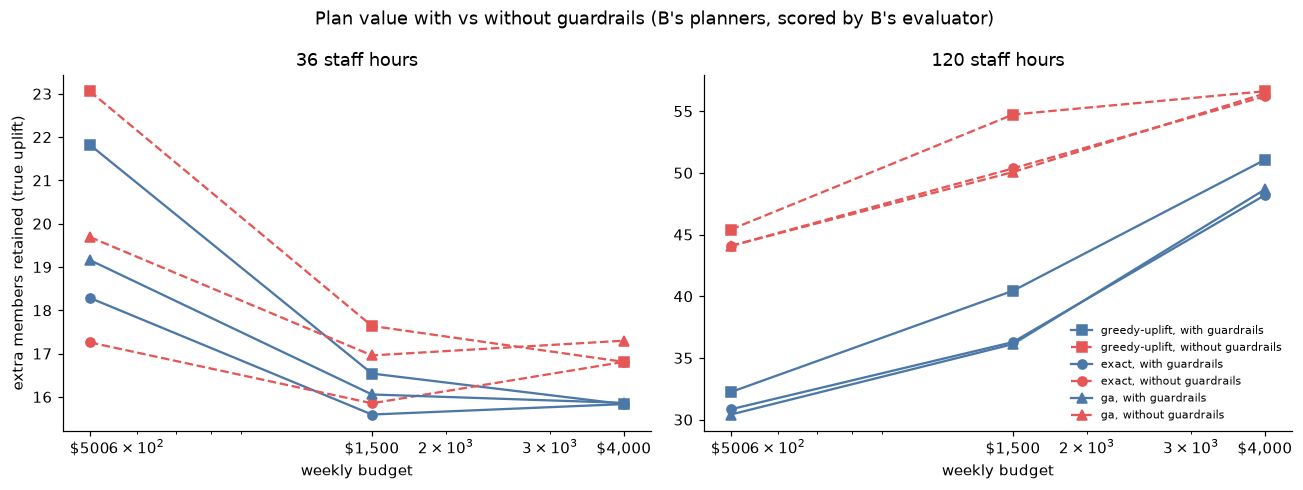

In [15]:
fig, axes = plt.subplots(1, len(STAFF_HOURS), figsize=(12, 4.5), sharey=False)
style = {"greedy-uplift": "s", "exact": "o", "ga": "^"}
for ax, hours in zip(axes, STAFF_HOURS):
    v = value.loc[hours]
    for planner, marker in style.items():
        for name, colour in [("with guardrails", "#4c78a8"), ("without guardrails", "#e45756")]:
            ax.plot(BUDGETS, v.xs(planner, level="planner")[name], marker=marker, color=colour,
                    ls="-" if name == "with guardrails" else "--", label=f"{planner}, {name}")
    ax.set_xscale("log")
    ax.set_xticks(BUDGETS, [f"${b:,}" for b in BUDGETS])
    ax.set_xlabel("weekly budget")
    ax.set_title(f"{hours} staff hours")
axes[0].set_ylabel("extra members retained (true uplift)")
axes[-1].legend(frameon=False, fontsize=7)
fig.suptitle("Plan value with vs without guardrails (B's planners, scored by B's evaluator)")
fig.tight_layout()
fig.savefig(FIG / "e6_plan_value.png", bbox_inches="tight")

**Look for:**

- The gap column is the **cost of the guardrails** in true retention, set against **what they prevent** (violations per
  guardrail-free plan: contacts inside the 30-day cap, repeat offers, repeat free PT, paid offers to low-risk members).
- The guardrail-free plan has a superset of candidates, so it should retain at least as many *by the planner's estimate*
  (`estimated_extra` in `runs`). By the **true** uplift it can retain fewer: the extra candidates are chosen on noisy CBR
  estimates, so a negative gap means the guardrails removed contacts the estimates over-valued, not that guardrails add value.
- At 36 h the budget columns barely move (staff time binds); at 120 h they should.

## 5. Findings

From the run on 2026-10-20: A's 2026-10-17 data (out-of-fold scores: 2,861 low / 169 medium / 970 high), the rule base
after the C1–C5 review fixes, and contacts logged in the app counted in the contact facts. The app DB holds Stream B's demo
week (`anchorai db reset`): an approved plan for the week of 2026-10-12 with 182 logged outcomes (69 accepted, 70 declined,
27 no answer, 16 follow-up). Part 4 uses Stream B's planners and evaluator.

1. **Validator and cases.** 29 rules, 0 validator issues; 29 of 29 scenario cases match the shipped rules.
2. **`G02_offer_cap` now fires, but removes nothing.** With the demo week's logged contacts counted, 45 members have 2 offers
   in 90 days (an earlier scenario offer plus the demo week; 0 before), so `at_offer_cap` is reachable on real data, not only
   in the scenario cases. All 45 were contacted in the demo week, so G01 already blocks every offer for them, and the trace
   names G01. G02 would bite on its own only for a member with two offers more than 30 days apart; the data has none yet.
3. **`G03_discount_eligibility` never removes a proposal.** Its only proposers, P05 and P05b, already require
   `contract_period == 1`, so G03 matches 1,793 members but blocks nothing the playbooks propose. It is a safety net for
   manual plan overrides (HANDOFFS #12) and future playbooks, not a working guardrail today.
4. **What guardrails actually do:** of 3,448 proposals, 1,080 (31.3%) are removed: 1,029 by `G01_contact_fatigue`
   (372 members), 44 by `G05_pt_eligibility` (30 members who had a free PT session in the last 90 days) and 7 by
   `G04_low_risk_no_paid_offers`. Before the logged contacts counted it was 528 (15.3%; G01 467 for 190 members): 657
   members are now inside the 30-day contact cap (475 from the scenario history plus the 182 contacted in the demo week),
   which is the point of #29: next week's plan cannot contact last week's members again. 300 of 970 high-risk members end
   with no allowed offer, 298 because G01 blocks every offer for them.
5. **74% of members have no allowed offer**, but 2,577 of those are low-risk members that no playbook targets (by design).
   Only 1 high-risk member has no playbook at all.
6. **Medium risk is a thin band** (169 members, 4.2%). P08 targets only medium-risk members (169 with its email twin); P04
   and P07 act on both medium- and high-risk members.
7. **No phone, no SMS or call.** The 386 members without a phone on file get the email or in-person twin of each playbook
   instead (338 twin firings, led by P06b's in-person PT for 100 members and P05b's emailed discount for 89). No member
   without a phone is proposed an SMS or a call.
8. **No opt-out fact** exists, so "never contact opted-out members" cannot be expressed (see part 2). Decided: out
   of scope, stated in the report.
9. **Low-risk new-and-slipping members** (P01, P01b) are proposed a PT session and then blocked by G04 (7 cases; P02 now
   proposes a free check-in, which G04 allows). Decided:
   **keep G04 as is.** The churn model already weighs tenure heavily (months as a member is a top driver), so a new
   member it still scores low risk is not worth a paid session. G04 blocks only paid offers, so free contacts are
   unaffected, and the blocked proposals stay visible in the trace so staff can see the choice.
10. **With vs without guardrails (counts):** switching the guardrails off gives 1,422 members an offer instead of 1,045,
    and 2,907 offers instead of 2,025. The 882 extra offers (30.3% of the guardrail-free set) are 845 contacts inside the
    30-day cap (G01), 30 repeat free PT sessions (G05) and 7 paid offers to low-risk members (G04).
11. **Plan value (part 4, B's planners and evaluator).** Extra members retained by the true uplift:

    | staff time | budget | with guardrails | without | gap | G01 violations per free plan |
    |---|---|---|---|---|---|
    | 36 h | $500-$4,000 | 15.6-21.8 | 15.9-23.1 | −1.0 to +1.4 (−6% to +9%) | 75-148 |
    | 120 h | $500-$4,000 | 30.4-51.1 | 44.1-56.6 | +5.6 to +14.3 (+11% to +45%) | 230-287 |

    At the seeded 36 h, staff time binds and removing the guardrails gains about one member at most, while every
    guardrail-free plan contacts 75-148 members a second time within 30 days. At 120 h the gap is large (13-14 members at
    $500-$1,500, 6-8 at $4,000) because the free plans spend the extra hours on members inside the 30-day cap (the demo week's
    182 among them). All the
    violations are G01: no planner picks a repeat free PT or a paid offer to a low-risk member. **The big caveat:** the
    scenario's true uplift has no contact-fatigue effect, so re-contacting a member reached last week is worth as much as
    a first contact. The gap is therefore the cost of G01 under a simulator that cannot see what G01 protects against, an
    upper bound, and the guardrails' benefit is not measurable here. Which planner wins is B's E4 question; here
    `greedy-uplift` matches or beats `exact` and `ga` on true value in most cells, consistent with B's finding that the CBR
    estimates are noisy.
12. **Rule changes from the interviews** (2026-10-16): D01 covers 72 members (was 127), D03 315 (was 502; members who
    always came rarely are no longer flagged) and the new D04 258 new members who are barely visiting. P07 reaches 271
    members by SMS and 28 more by email.
